In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [3]:
import pickle

def unpickle(file):
    with open(file, 'rb') as fo:
        return pickle.load(fo, encoding='bytes')

# 5 training batches -> 50,000 images
xs, ys = [], []
for i in range(1, 6):
    b = unpickle(f'data_batch_{i}')
    xs.append(b[b'data'])
    ys += b[b'labels']
X_train_full = np.concatenate(xs).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)  # (50000,32,32,3) uint8
y_train_full = np.array(ys)

# official test batch -> 10,000 images
t = unpickle('test_batch')
X_test = t[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_test = np.array(t[b'labels'])

classes = [n.decode() for n in unpickle('batches.meta')[b'label_names']]
print('train', X_train_full.shape, 'test', X_test.shape)
print(classes)

train (50000, 32, 32, 3) test (10000, 32, 32, 3)
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [21]:
from sklearn.model_selection import StratifiedShuffleSplit

SEED = 42

# Match the ML notebook EXACTLY: same function (StratifiedShuffleSplit),

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_idx, val_idx = next(splitter.split(np.zeros(len(y_train_full)), y_train_full))

# save for sharing / documentation
np.save('train_idx.npy', train_idx)
np.save('val_idx.npy', val_idx)

print('train', len(train_idx), 'val', len(val_idx))
print('val class balance', np.bincount(y_train_full[val_idx]))

train 45000 val 5000
val class balance [500 500 500 500 500 500 500 500 500 500]


In [13]:
from PIL import Image

# ResNet expects 224x224 + ImageNet normalization
train_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),                 # light augmentation
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class CIFAR10Set(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        img = Image.fromarray(self.images[i])          # uint8 HWC -> PIL
        return self.transform(img), int(self.labels[i])

train_set = CIFAR10Set(X_train_full[train_idx], y_train_full[train_idx], train_tf)
val_set   = CIFAR10Set(X_train_full[val_idx],   y_train_full[val_idx],   eval_tf)
test_set  = CIFAR10Set(X_test, y_test, eval_tf)

# num_workers=0 avoids Windows/Jupyter multiprocessing issues; bump to 2 if it runs fine
train_loader = DataLoader(train_set, batch_size=64, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=64, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False, num_workers=0, pin_memory=True)
print('batches:', len(train_loader), len(val_loader), len(test_loader))

batches: 704 79 157


In [14]:
from torchvision.models import resnet18, ResNet18_Weights

# ImageNet weights — NOT trained on CIFAR-10, so allowed by the assignment
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 10)   # 1000 ImageNet classes -> 10 CIFAR classes
model = model.to(device)
print('final layer:', model.fc)

final layer: Linear(in_features=512, out_features=10, bias=True)


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
EPOCHS = 5

def accuracy(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total

train_losses = []
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), labels)
        loss.backward()
        optimizer.step()
        running += loss.item()
    avg = running / len(train_loader)
    train_losses.append(avg)
    print(f'epoch {epoch+1}/{EPOCHS}  train_loss {avg:.4f}  val_acc {accuracy(val_loader):.4f}')

epoch 1/5  train_loss 0.3410  val_acc 0.9410
epoch 2/5  train_loss 0.1350  val_acc 0.9400
epoch 3/5  train_loss 0.0886  val_acc 0.9428
epoch 4/5  train_loss 0.0599  val_acc 0.9442
epoch 5/5  train_loss 0.0453  val_acc 0.9418


In [16]:
torch.save(model.state_dict(), 'resnet18_cifar10.pth')
print('saved resnet18_cifar10.pth')

saved resnet18_cifar10.pth


TEST accuracy: 0.9416


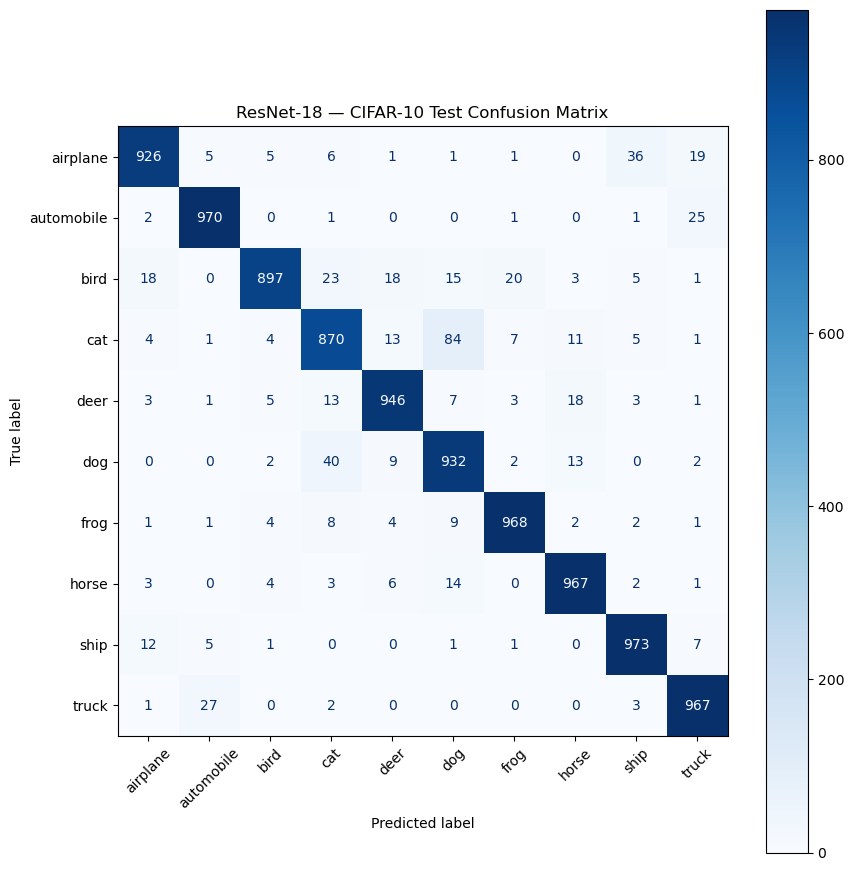

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = (all_preds == all_labels).mean()
print(f'TEST accuracy: {test_acc:.4f}')

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=45, cmap='Blues')
plt.title('ResNet-18 — CIFAR-10 Test Confusion Matrix')
plt.tight_layout()
plt.show()

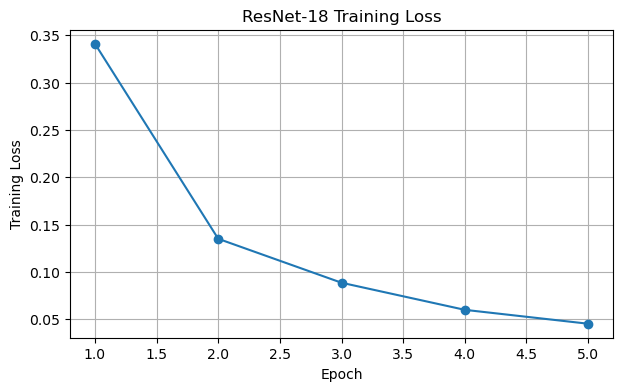

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Training Loss')
plt.title('ResNet-18 Training Loss')
plt.grid(True); plt.show()

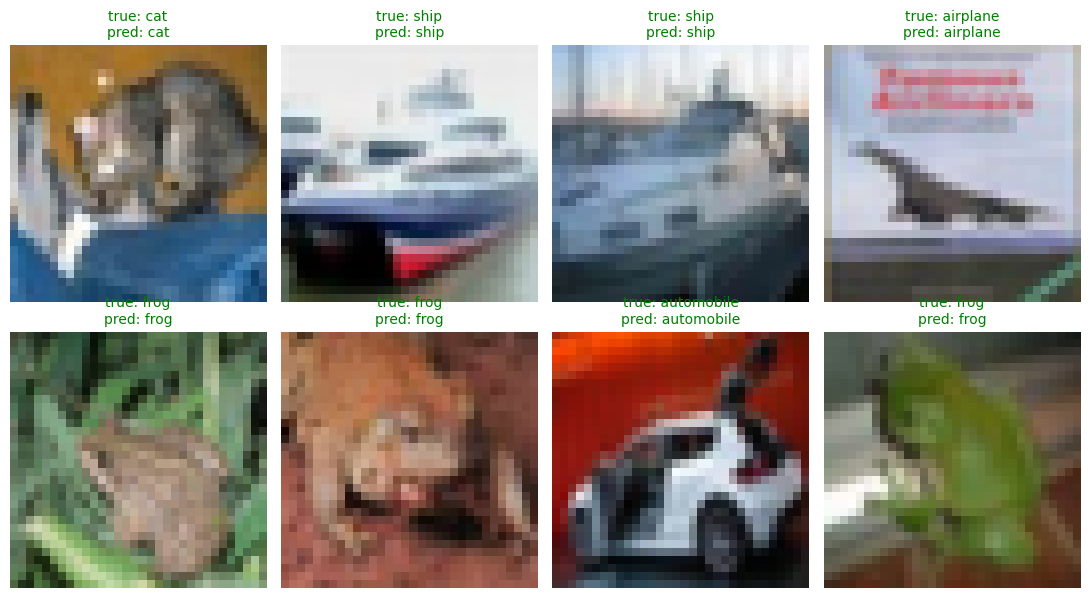

In [20]:
# raw (un-normalized) images for display + matching labels from the test set
inv_idx = np.arange(8)
imgs_disp = X_test[inv_idx]                      # uint8 32x32x3, for showing
batch = torch.stack([eval_tf(Image.fromarray(im)) for im in imgs_disp]).to(device)

model.eval()
with torch.no_grad():
    pred = model(batch).argmax(1).cpu().numpy()

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs_disp[i])
    true_c, pred_c = classes[y_test[inv_idx[i]]], classes[pred[i]]
    color = 'green' if true_c == pred_c else 'red'
    ax.set_title(f'true: {true_c}\npred: {pred_c}', color=color, fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()